# Galaxy SNR estimation 2 cases

We will model the Sersic profile of a compact early-type galaxy. See Sersic profile lecture: https://ned.ipac.caltech.edu/level5/March05/Graham/Graham2.html

In [28]:
import astropy.units as u

from astropy.modeling.models import Sersic2D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Sersic2D.html

In [29]:
from matplotlib import pyplot as plt
import numpy as np
from scipy import special #import jv, kv
# from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate

In [30]:
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0

In [31]:
from scipy.optimize import brentq
from scipy.optimize import fminbound

In [32]:
from dataclasses import dataclass
import pandas as pd

In [33]:
from joblib import Parallel, delayed
import os

## Import functions

In [34]:
import sys
from pathlib import Path

src_path = Path("/Users/tliu/oh_suppression/codes/src")

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from oh_suppression.coupling import *

In [ ]:
from oh_suppression.point_source_coupling import *
from oh_suppression.flat_background_coupling import *
from oh_suppression.extended_source_coupling import *

## Begin Work

In [36]:
# wavelength of beam in vacuum
lam0 = 1.5e-6 
# fibre core radius
a = 5e-6 
# numerical aperture of fibre
NA = 0.1 

# Calculate the normalised frequency (V-number) of the fibre
V = 2 * pi * (a / lam0) * NA
print(f"V-number of the fibre: {V:.2f}")

V-number of the fibre: 2.09


In [37]:
V_max_single = 2.405 # The cutoff V-number for single-mode operation in a step-index fibre
a_max_single = V_max_single * lam0 / (2 * np.pi * NA)
print(f"Maximum core radius for single-mode operation: {a_max_single*1e6:.20f} microns")

Maximum core radius for single-mode operation: 5.74151457204012416469 microns


In [38]:
NA = 0.1
F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))
Magnification = F_fibre / 49.9
F_focus = 49.9

D_M1 = 8.0 # Diameter of the primary mirror in meters
D_obstruction = 1.0 # Diameter of the central obstruction in meters
alpha_vlt = D_obstruction / D_M1 # Ratio of the central obstruction to the primary mirror diameter (0.125 for VLT)
rad_to_arcsec = (180 / np.pi) * 3600
plate_scale_coude = rad_to_arcsec / (F_focus * D_M1)  # arcsec / metre at telescope focal plane
plate_scale_demag = plate_scale_coude / Magnification # arcsec / metre at the demagnified fibre input plane

In [39]:
print(f"Plate scale at the Coudé focus: {plate_scale_coude*1e-3:.2f} arcsec/mm")

Plate scale at the Coudé focus: 0.52 arcsec/mm


In [40]:
core_radius_range_test = np.arange(2.5e-6, 5.74e-6 + 0.01e-6, 0.01e-6) # range of core radius to test, from 2.5 microns to 5.7415 microns, in steps of 0.01 microns. Note arange is exclusive of the upper limit, so we add 0.01e-6 to include 5.74e-6 in the range. 
lam0 = 1.5e-6 # wavelength of beam in vacuum 

## Galaxy profile

In [41]:
path = '/Users/tliu/oh_suppression/data/data_CANDELS_structural_param_galaxies/ID18941_matched_rows.csv'
df = pd.read_csv(path)
df

,Fld,F,ID,W,RAJ2000,DEJ2000,Q,mag,e_mag,r,e_r,n,e_n,q,PA,S_N,COSMOS,GOODS,recno
0,G,H,18941,W,53.152779,-27.750511,0,22.224,0.009,0.101,0.002,3.335,0.130,0.514,-88.7,327.52,0,1,90805
1,G,J,18941,W,53.152779,-27.750511,0,22.548,0.009,0.097,0.002,3.518,0.149,0.515,-88.9,312.57,0,1,125735
2,G,Y,18941,W,53.152779,-27.750511,0,22.886,0.010,0.094,0.002,3.073,0.150,0.472,-86.7,272.72,0,1,160665


In [42]:
n_sersic = 3.335 # sersic index, n>0.36
Re_arcsec = 0.101 # half light radius in arcseconds
q_param = 0.514 # projected axis ratio of the galaxy, b/a, where b is the semi-minor axis and a is the semi-major axis. This is used to calculate the effective radius in the direction of the fibre input plane.
# PA = 0 # assumed to be 0 for simplicity, but can be adjusted based on the orientation of the galaxy in the sky.
PA_deg = -88.7
ellip = 1 - q_param # ellipticity of the galaxy, defined as 1 - (b/a)

In [43]:
# Sersic profile has a scaling constant b_n, for n>0.36, b_n can be approximated as b_n = 2n - 1/3 + 4/(405n) + 46/(25515n^2) + 131/(1148175n^3) 
# - 2194697/(30690717750n^4)
b_n = 2 * n_sersic - 1/3 + 4/(405*n_sersic) + 46/(25515*n_sersic**2) + 131/(1148175*n_sersic**3) - 2194697/(30690717750*n_sersic**4)

The intensity of a profile of galaxy at the image plane: 

$$
I(R) = I_e \exp\left[
-b_n \left(
\left(\frac{R}{R_e}\right)^{1/n} - 1
\right)
\right]
$$

At the fibre front in grids: 

$$
I(x,y) = I_e \exp\left[
-b_n \left(
\left(\frac{R_{\mathrm{ell}}(x,y)}{R_e}\right)^{1/n} - 1
\right)
\right],
$$

For galaxy with a elliptical radius $R_{ell}$: 

$$
R_{\mathrm{ell}}(x,y)
=
\sqrt{
x'^2 + \left(\frac{y'}{q}\right)^2
}.
$$

where $q = \frac{b}{a}$

In [44]:
Sersic2D?

Init signature:
Sersic2D(
    amplitude=1,
    r_eff=1,
    n=4,
    x_0=0,
    y_0=0,
    ellip=0,
    theta=0.0,
    **kwargs,
)
Docstring:     
Two dimensional Sersic surface brightness profile.

Parameters
----------
amplitude : float
    Surface brightness at ``r_eff``.
r_eff : float
    Effective (half-light) radius.
n : float
    Sersic index controlling the shape of the profile. Particular
    values of ``n`` are equivalent to the following profiles:

        * n=4 : `de Vaucouleurs <https://en.wikipedia.org/wiki/De_Vaucouleurs%27s_law>`_ :math:`r^{1/4}` profile
        * n=1 : Exponential profile
        * n=0.5 : Gaussian profile
x_0 : float, optional
    x position of the center.
y_0 : float, optional
    y position of the center.
ellip : float, optional
    Ellipticity of the isophote, defined as 1.0 minus the ratio of
    the lengths of the semimajor and semiminor axes:

    .. math:: ellip = 1 - \frac{b}{a}
theta : float or `~astropy.units.Quantity`, optional
    The rota

In [45]:
# Fibre front grid in metres

r_max = 125e-6 # maximum radius of the CLADDING region to be considered in the 2D grid, in meters
n_grid = 1000 

x_1d = np.linspace(-r_max, r_max, n_grid)
y_1d = np.linspace(-r_max, r_max, n_grid)

x, y = np.meshgrid(x_1d, y_1d)

In [46]:
FOV_test = plate_scale_demag * 2 * r_max
FOV_test_smf = plate_scale_demag * 2 * 5.7e-6
print(f"Test FOV: {FOV_test:.4f} arcsec")
print(f"Test FOV for SMF: {FOV_test_smf:.4f} arcsec")

Test FOV: 1.2956 arcsec
Test FOV for SMF: 0.0591 arcsec


In [47]:
# Angular grid for the Sersic profile, in radians

# angular_extent = 0.5 # arcsec (I should probably find the FOV of a 125e-6m light bucket)
angular_extent = 1.30/2 # arcsec, which is half of the FOV of a 125e-6m light bucket at the Coudé focus, based on the plate scale calculated above.

x_arcsec_1d = np.linspace(-angular_extent, angular_extent, n_grid)
y_arcsec_1d = np.linspace(-angular_extent, angular_extent, n_grid)

x_arcsec, y_arcsec = np.meshgrid(x_arcsec_1d, y_arcsec_1d)

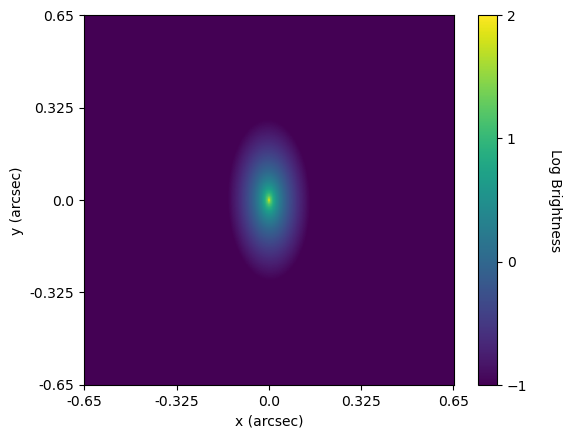

In [48]:
model_cent = Sersic2D(amplitude=1, r_eff = Re_arcsec, n = n_sersic, x_0=0, y_0=0, ellip=ellip, theta=np.radians(PA_deg))

# img is a numpy array of the Sersic profile evaluated at each point in the 2D grid defined by x_arcsec and y_arcsec. 
img = model_cent(x_arcsec, y_arcsec)
log_img = np.log10(img)

fig, ax = plt.subplots()
im = ax.imshow(log_img, origin='lower', interpolation='nearest',
               vmin=-1, vmax=2)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Log Brightness', rotation=270, labelpad=25)
# Set ticks in arcseconds for the x and y axes
ax.set_xticks(np.linspace(0, n_grid-1, 5))
ax.set_xticklabels(np.round(np.linspace(-angular_extent, angular_extent, 5), 3))
ax.set_yticks(np.linspace(0, n_grid-1, 5))
ax.set_yticklabels(np.round(np.linspace(-angular_extent, angular_extent, 5), 3))
cbar.set_ticks([-1, 0, 1, 2])
plt.xlabel('x (arcsec)')
plt.ylabel('y (arcsec)')
plt.show()

In [49]:
# model_cent?

## Testing SNR vs Core radius for two cases: 

 - integrate extended source to core
 - integrate extended source to cladding

In [50]:
core_radius_range_full = np.arange(2.5e-6, 30e-6+0.1e-6, 0.1e-6) # range of core radius to test, from 2.5 microns to 30 microns, in 100 steps. This is a more comprehensive range than the previous test range.
core_radius_range_full

array([2.50e-06, 2.60e-06, 2.70e-06, 2.80e-06, 2.90e-06, 3.00e-06,
       3.10e-06, 3.20e-06, 3.30e-06, 3.40e-06, 3.50e-06, 3.60e-06,
       3.70e-06, 3.80e-06, 3.90e-06, 4.00e-06, 4.10e-06, 4.20e-06,
       4.30e-06, 4.40e-06, 4.50e-06, 4.60e-06, 4.70e-06, 4.80e-06,
       4.90e-06, 5.00e-06, 5.10e-06, 5.20e-06, 5.30e-06, 5.40e-06,
       5.50e-06, 5.60e-06, 5.70e-06, 5.80e-06, 5.90e-06, 6.00e-06,
       6.10e-06, 6.20e-06, 6.30e-06, 6.40e-06, 6.50e-06, 6.60e-06,
       6.70e-06, 6.80e-06, 6.90e-06, 7.00e-06, 7.10e-06, 7.20e-06,
       7.30e-06, 7.40e-06, 7.50e-06, 7.60e-06, 7.70e-06, 7.80e-06,
       7.90e-06, 8.00e-06, 8.10e-06, 8.20e-06, 8.30e-06, 8.40e-06,
       8.50e-06, 8.60e-06, 8.70e-06, 8.80e-06, 8.90e-06, 9.00e-06,
       9.10e-06, 9.20e-06, 9.30e-06, 9.40e-06, 9.50e-06, 9.60e-06,
       9.70e-06, 9.80e-06, 9.90e-06, 1.00e-05, 1.01e-05, 1.02e-05,
       1.03e-05, 1.04e-05, 1.05e-05, 1.06e-05, 1.07e-05, 1.08e-05,
       1.09e-05, 1.10e-05, 1.11e-05, 1.12e-05, 1.13e-05, 1.14e

In [51]:
np.shape(core_radius_range_full)

(276,)

In [52]:
I_galaxy = np.zeros_like(core_radius_range_full)  # Initialize an array to store galaxy brightness for each core radius

eta_galaxy_core = np.zeros_like(core_radius_range_full)  # Initialize an array to store coupling efficiencies for each core radius
eta_galaxy_cladding = np.zeros_like(core_radius_range_full)  # Initialize an array to store coupling efficiencies for each core radius

eta_background_core = np.zeros_like(core_radius_range_full)  # Initialize an array to store background coupling efficiencies for each core radius
eta_background_cladding = np.zeros_like(core_radius_range_full)  # Initialize an array to store background coupling efficiencies for each core radius

V_norm_array = np.zeros_like(core_radius_range_full)  # Initialize an array to store normalized frequencies for each core radius

In [188]:
# background_efficiency_vs_core_radius_2d?

In [55]:
# core_radius_test_small = np.linspace(1.2e-6, 20e-6, 80)
results_bg_mmf_clad = background_efficiency_vs_core_radius_2d(
    core_radius_array=core_radius_range_full,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    NA=NA,
    lam0=lam0,
    alpha=alpha_vlt,
    az_sym=False,
    mode_case="few_mode",
    decentre_max=None,
    n_decentre=40,
    E_S=1.0,
    n_F_grid=60, 
    n_jobs=4, 
)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    5.9s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    8.5s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   14.3s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:   18.0s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:   25.5s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   37.1s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:   49.0s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:  1.0min
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:  1.4min
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:  1.8min
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:  2.3min
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:  3.1min
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:  4.1min
/Users/tliu/.conda/envs/oh_suppression_env/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: 

In [56]:
# core_radius_test_small = np.linspace(1.2e-6, 20e-6, 80)
results_bg_mmf_core = background_efficiency_vs_core_radius_2d(
    core_radius_array=core_radius_range_full,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    NA=NA,
    lam0=lam0,
    alpha=alpha_vlt,
    az_sym=False,
    mode_case="few_mode",
    decentre_max="core_radius",
    n_decentre=40,
    E_S=1.0,
    n_F_grid=60, 
    n_jobs=6, 
)

[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done   1 tasks      | elapsed:    4.3s
[Parallel(n_jobs=6)]: Done   6 tasks      | elapsed:    4.5s
[Parallel(n_jobs=6)]: Done  13 tasks      | elapsed:   12.7s
[Parallel(n_jobs=6)]: Done  20 tasks      | elapsed:   17.0s
[Parallel(n_jobs=6)]: Done  29 tasks      | elapsed:   21.3s
[Parallel(n_jobs=6)]: Done  38 tasks      | elapsed:   32.8s
[Parallel(n_jobs=6)]: Done  49 tasks      | elapsed:   47.8s
[Parallel(n_jobs=6)]: Done  60 tasks      | elapsed:  1.0min
[Parallel(n_jobs=6)]: Done  73 tasks      | elapsed:  1.4min
[Parallel(n_jobs=6)]: Done  86 tasks      | elapsed:  1.9min
[Parallel(n_jobs=6)]: Done 101 tasks      | elapsed:  2.4min
[Parallel(n_jobs=6)]: Done 116 tasks      | elapsed:  3.1min
[Parallel(n_jobs=6)]: Done 133 tasks      | elapsed:  4.0min
[Parallel(n_jobs=6)]: Done 150 tasks      | elapsed:  5.1min
[Parallel(n_jobs=6)]: Done 169 tasks      | elapsed:  6.4min
[Parallel(

In [60]:
def radial_efficiency_to_2d(decentre_array, eta_point_source, x, y, fibre_x=0.0, fibre_y=0.0):
    """
    Convert a radial efficiency profile to a 2D efficiency map.

    Parameters:
    decentre_array: 1D array of radial distances from the fibre centre [m]
    eta_point_source: 1D array of coupling efficiencies corresponding to decentre_array
    x, y: 2D coordinate arrays at the fibre input plane [m]
    fibre_x, fibre_y: coordinates of the fibre centre in the x-y grid [m]

    Returns:
    eta_2d: 2D array of coupling efficiencies at each point in the x-y grid
    """

    # Calculate the radial distance from the fibre centre for each point in the grid
    R = np.sqrt((x - fibre_x)**2 + (y - fibre_y)**2)

    # Interpolate the radial efficiency profile onto the 2D grid
    eta_map_2d = np.interp(R.ravel(), decentre_array, eta_point_source, left=eta_point_source[0], right=eta_point_source[-1]).reshape(R.shape)

    return eta_map_2d


In [61]:
def eta_extended_source_2d(
    eta_map_2d,
    galaxy_brightness_2d,
    x_1d,
    y_1d,
):
    """
    Calculate the coupling efficiency of an incoherent extended source
    into a fibre.

    Parameters
    ----------
    eta_map_2d : 2D array
        Point-source coupling efficiency evaluated across the x-y grid.

    galaxy_brightness_2d : 2D array
        Linear galaxy brightness distribution evaluated on the same grid.

    x_1d, y_1d : 1D arrays
        Coordinates of the x and y grid axes.

    Returns
    -------
    eta_extended : float
        Brightness-weighted coupling efficiency of the extended source.
    """

    weighted_function = (
        eta_map_2d
        * galaxy_brightness_2d
    )

    # First integrate along x, then along y
    weighted_sum = integrate.simpson(
        integrate.simpson(
            weighted_function,
            x=x_1d,
            axis=1,
        ),
        x=y_1d,
    )

    total_brightness = integrate.simpson(
        integrate.simpson(
            galaxy_brightness_2d,
            x=x_1d,
            axis=1,
        ),
        x=y_1d,
    )

    eta_extended = weighted_sum / total_brightness

    return eta_extended

In [ ]:
def extended_source_no_opt_efficiency_at_one_radius_2d(
        a,
        x, y, x_1d, y_1d, 
        NA, lam0, I_source, 
        alpha=0.0, 
        az_sym=True, 
        mode_case="smf", 
        decentre_max=None, 
        n_decentre=50, E_S=1.0, 
        n_F_grid=60, 
        F_eff=F_fibre,
):
    """
    For one fibre core radius a: 
        1. Prepare fibre modes
        2. Calculate eta_psf(d)
        3. Integrate eta_psf(d) to get coupling effieciency for an extended source with a given brightness distribution

    Parameters:
    decentre_max: the maximum decentre radius, set to None, but equals to the cladding radius
    n_decentre: the number of decentre points to consider
    E_S: the electric field amplitude of the point source
    n_F_grid: the number of grid points for the F_eff calculation
    I_source: the intensity distribution of the extended source, 2d numpy array, same shape as x and y grids

    """

    V = 2 * np.pi * a * NA / lam0

    prepared_modes = prepare_modes_2d(
        x, y, 
        a=a, 
        NA=NA, 
        lam0=lam0,
        az_sym=az_sym, 
        mode_case=mode_case
    )

    eta_centre, mode_results_centred = total_eff_2d(
        prepared_modes,
        x=x, y=y, x_1d=x_1d, y_1d=y_1d,
        lam0=lam0,
        F_eff=F_fibre,
        alpha=alpha,
        decentre=None,
        E_S=E_S
    )

    E_image_opt, I_image_opt = diffraction_limited_E_field_at_fibre_2d(
        x, y,
        lam0=lam0,
        F_eff=F_fibre,
        alpha=alpha,
        E_S=E_S,
        decentre=None
    )

    # Choose decentre_max to be the cladding radius if not specified
    if decentre_max is None: 
        r_max = 125e-6 # in meters, this is the maximum radius of the grid we prepared for the field calculations, so we can't go beyond this
        decentre_max = r_max # cladding radius 

    elif decentre_max == "core_radius": 
        decentre_max = a # core radius

    decentre_array = np.linspace(0, decentre_max, n_decentre)

    # Calculate eta_psf(d) for the range of decentre values
    eta_psf,  mode_results_decentre = eta_psf_vs_radial_decentre_position(
        prepared_modes, 
        x, y, x_1d, y_1d,
        lam0=lam0, F_eff=F_fibre, alpha=alpha,
        decentre_array=decentre_array,
        E_S=E_S
    )

    # Integrate over the extended source brightness distribution to get the coupling efficiency for the extended source
    eta_map_2d=radial_efficiency_to_2d(decentre_array, eta_psf, x, y)

    eta_extended_source = eta_extended_source_2d(eta_map_2d=eta_map_2d,
        galaxy_brightness_2d=I_source, x_1d=x_1d, y_1d=y_1d)
    
    return {
        "a": a,
        "V": V,
        "F_eff": F_fibre,
        "eta_centre": eta_centre,
        "eta_extended_source": eta_extended_source,
        "decentre_array": decentre_array,
        "eta_psf": eta_psf,
        "mode_results_centred": mode_results_centred,
        "mode_results_decentre": mode_results_decentre,
        "E_image_opt": E_image_opt,
        "I_image_opt": I_image_opt
    }

In [63]:
def extended_source_efficiency_vs_core_radius_2d(
        core_radius_array, 
        x, y, x_1d, y_1d,
        NA, lam0, I_source,
        alpha=0.0,
        az_sym=True,
        mode_case="smf",
        decentre_max=None,
        n_decentre=50, 
        E_S=1.0, 
        n_F_grid=60,
        n_jobs=1
):
    """
    Loop over core radius and calculate: 
        - centred point source efficiency at optimal F
        - extended source efficiency by the weighted average of a number of decentred point source efficiencies
    
    Parameters: 

    core_radius_array: array of core radius values to process
    x, y, x_1d, y_1d: grid points for the field calculations
    NA: numerical aperture 
    lam0: wavelength
    alpha: central obstruction ratio
    az_sym: whether to use azimuthal symmetry
    mode_case: case for mode calculation
    decentre_max: maximum decentre radius
    n_decentre: number of decentre points
    E_S: electric field amplitude of the point source
    n_F_grid: number of grid points for F_eff calculation
    n_jobs: number of parallel workers. Use 1 for serial, >1 for parallel.

    """

    n_total = len(core_radius_array)

    # if decentre_max is None:
    #     angular_extent = 1.30/2 # arcsec, which is half of the FOV of a 125e-6m light bucket at the Coudé focus, based on the plate scale calculated above.
    #     model_cent = Sersic2D(amplitude=1, r_eff = Re_arcsec, n = n_sersic, x_0=0, y_0=0, ellip=ellip, theta=np.radians(PA_deg))

    #     x_arcsec_1d = np.linspace(-angular_extent, angular_extent, n_grid)
    #     y_arcsec_1d = np.linspace(-angular_extent, angular_extent, n_grid)

    #     x_arcsec, y_arcsec = np.meshgrid(x_arcsec_1d, y_arcsec_1d)
        
    #     I_source = model_cent(x_arcsec, y_arcsec) # 2D array of the Sersic profile evaluated at each point in the 2D grid defined by x_arcsec and y_arcsec.
    
    # elif decentre_max == "core_radius":
    #     FOV_test_smf = plate_scale_demag * 2 * a
    #     angular_extent = FOV_test_smf / 2 # arcsec, which is half of the FOV of a 125e-6m light bucket at the Coudé focus, based on the plate scale calculated above.
    #     model_cent = Sersic2D(amplitude=1, r_eff = Re_arcsec, n = n_sersic, x_0=0, y_0=0, ellip=ellip, theta=np.radians(PA_deg))

    #     x_arcsec_1d = np.linspace(-angular_extent, angular_extent, n_grid)
    #     y_arcsec_1d = np.linspace(-angular_extent, angular_extent, n_grid)

    #     x_arcsec, y_arcsec = np.meshgrid(x_arcsec_1d, y_arcsec_1d)
        
    #     I_source = model_cent(x_arcsec, y_arcsec) # 2D array of the Sersic profile evaluated at each point in the 2D grid defined by x_arcsec and y_arcsec.

    def run_one_radius(i, a):
        row = extended_source_no_opt_efficiency_at_one_radius_2d(
            a=a, 
            x=x, y=y, x_1d=x_1d, y_1d=y_1d,
            NA=NA, 
            lam0=lam0,
            I_source=I_source,
            alpha=alpha,
            az_sym=az_sym, 
            mode_case=mode_case,
            decentre_max=decentre_max, 
            n_decentre=n_decentre, 
            E_S=E_S,
            n_F_grid=n_F_grid, 
            F_eff=F_fibre
        )
        return row

    if n_jobs == 1:
        results = []

        checkpoints = {
            max(1, int(np.ceil(n_total * p / 10))) 
            for p in range(1, 11)
        }

        for i, a in enumerate(core_radius_array, start=0):
            results.append(run_one_radius(i,a))

            step=i + 1 # step is the number of core radiuses we have processed so far, starting from 1

            if i in checkpoints:
                percent = int(round(100 * step / n_total))
                print(f"{percent}% complete ({step}/{n_total})")

    else:
        results = Parallel(n_jobs=n_jobs, verbose=10)(
            delayed(run_one_radius)(i,a)
            for i, a in enumerate(core_radius_array, start=0)
        )

    return results


In [64]:
# Calclate the extended source coupling efficiency for the galaxy brightness distribution over the range of core radii
# Cladding case

results_ext_mmf_clad = extended_source_efficiency_vs_core_radius_2d(
    core_radius_array=core_radius_range_full,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    I_source=img,
    NA=NA,
    lam0=lam0,
    alpha=alpha_vlt,
    az_sym=False,
    mode_case="few_mode",
    decentre_max=None,
    n_decentre=40,
    E_S=1.0,
    n_F_grid=60,
    n_jobs=6,
)

[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.


[Parallel(n_jobs=6)]: Done   1 tasks      | elapsed:    4.2s
/Users/tliu/.conda/envs/oh_suppression_env/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=6)]: Done   6 tasks      | elapsed:    4.9s
[Parallel(n_jobs=6)]: Done  13 tasks      | elapsed:   13.6s
[Parallel(n_jobs=6)]: Done  20 tasks      | elapsed:   18.0s
[Parallel(n_jobs=6)]: Done  29 tasks      | elapsed:   23.5s
[Parallel(n_jobs=6)]: Done  38 tasks      | elapsed:   36.1s
[Parallel(n_jobs=6)]: Done  49 tasks      | elapsed:   52.0s
[Parallel(n_jobs=6)]: Done  60 tasks      | elapsed:  1.1min
[Parallel(n_jobs=6)]: Done  73 tasks      | elapsed:  1.4min
[Parallel(n_jobs=6)]: Done  86 tasks      | elapsed:  2.0min
[Parallel(n_jobs=6)]: Done 101 tasks      | elapsed:  2.5min
[Parallel(n_jobs=6)]: Done 116 tasks      | elaps

In [65]:
# Calclate the extended source coupling efficiency for the galaxy brightness distribution over the range of core radii
# Core case

results_ext_mmf_core = extended_source_efficiency_vs_core_radius_2d(I_source=img,
    core_radius_array=core_radius_range_full,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    NA=NA,
    lam0=lam0,
    alpha=alpha_vlt,
    az_sym=False,
    mode_case="few_mode",
    decentre_max="core_radius",
    n_decentre=40,
    E_S=1.0,
    n_F_grid=60,
    n_jobs=6,
)

[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done   1 tasks      | elapsed:    4.6s
[Parallel(n_jobs=6)]: Done   6 tasks      | elapsed:    5.6s
[Parallel(n_jobs=6)]: Done  13 tasks      | elapsed:   14.5s
[Parallel(n_jobs=6)]: Done  20 tasks      | elapsed:   19.8s
[Parallel(n_jobs=6)]: Done  29 tasks      | elapsed:   25.2s
[Parallel(n_jobs=6)]: Done  38 tasks      | elapsed:   36.7s
[Parallel(n_jobs=6)]: Done  49 tasks      | elapsed:   53.5s
[Parallel(n_jobs=6)]: Done  60 tasks      | elapsed:  1.1min
[Parallel(n_jobs=6)]: Done  73 tasks      | elapsed:  1.5min
[Parallel(n_jobs=6)]: Done  86 tasks      | elapsed:  2.0min
[Parallel(n_jobs=6)]: Done 101 tasks      | elapsed:  2.6min
[Parallel(n_jobs=6)]: Done 116 tasks      | elapsed:  3.4min
[Parallel(n_jobs=6)]: Done 133 tasks      | elapsed:  4.3min
[Parallel(n_jobs=6)]: Done 150 tasks      | elapsed:  5.6min
[Parallel(n_jobs=6)]: Done 169 tasks      | elapsed:  6.9min
[Parallel(

In [75]:
from pathlib import Path
from datetime import datetime
import joblib
import gc

# Create a new checkpoint folder under your non-GitHub result directory
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

checkpoint_dir = (
    Path("/Users/tliu/oh_suppression/result")
    / f"galaxy_snr_2_int_cases_checkpoint_{timestamp}"
)

checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("Saving checkpoint to:")
print(checkpoint_dir)

# Variables to save
checkpoint_vars = {
    "results_bg_mmf_clad": results_bg_mmf_clad,
    "results_bg_mmf_core": results_bg_mmf_core,
    "results_ext_mmf_clad": results_ext_mmf_clad,
    "results_ext_mmf_core": results_ext_mmf_core,
}

# Save each result separately
for name, obj in checkpoint_vars.items():
    save_path = checkpoint_dir / f"{name}.joblib"
    joblib.dump(obj, save_path, compress=0)
    print(f"Saved {name} -> {save_path}")

Saving checkpoint to:
/Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343
Saved results_bg_mmf_clad -> /Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_clad.joblib
Saved results_bg_mmf_core -> /Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_core.joblib
Saved results_ext_mmf_clad -> /Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_ext_mmf_clad.joblib
Saved results_ext_mmf_core -> /Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_ext_mmf_core.joblib


In [76]:
for file in checkpoint_dir.glob("*.joblib"):
    size_gb = file.stat().st_size / 1024**3
    print(f"{file.name}: {size_gb:.3f} GB")

results_bg_mmf_core.joblib: 4.125 GB
results_ext_mmf_clad.joblib: 4.125 GB
results_bg_mmf_clad.joblib: 4.125 GB
results_ext_mmf_core.joblib: 4.125 GB


In [77]:
test_bg_clad = joblib.load(checkpoint_dir / "results_bg_mmf_clad.joblib")
test_bg_core = joblib.load(checkpoint_dir / "results_bg_mmf_core.joblib")
test_ext_clad = joblib.load(checkpoint_dir / "results_ext_mmf_clad.joblib")
test_ext_core = joblib.load(checkpoint_dir / "results_ext_mmf_core.joblib")

print("Load test successful.")
print("Length results_bg_mmf_clad:", len(test_bg_clad))
print("Length results_bg_mmf_core:", len(test_bg_core))
print("Length results_ext_mmf_clad:", len(test_ext_clad))
print("Length results_ext_mmf_core:", len(test_ext_core))

# Remove test-loaded copies immediately so they do not double your RAM usage
del test_bg_clad, test_bg_core, test_ext_clad, test_ext_core
gc.collect()

Load test successful.
Length results_bg_mmf_clad: 276
Length results_bg_mmf_core: 276
Length results_ext_mmf_clad: 276
Length results_ext_mmf_core: 276


0

In [78]:
latest_path_file = Path("/Users/tliu/oh_suppression/result/latest_galaxy_snr_checkpoint.txt")

with open(latest_path_file, "w") as f:
    f.write(str(checkpoint_dir))

print("Latest checkpoint path saved to:")
print(latest_path_file)

Latest checkpoint path saved to:
/Users/tliu/oh_suppression/result/latest_galaxy_snr_checkpoint.txt


In [79]:
del results_bg_mmf_clad
del results_bg_mmf_core
del results_ext_mmf_clad
del results_ext_mmf_core

gc.collect()

print("Deleted large result variables from current notebook namespace.")

Deleted large result variables from current notebook namespace.


In [89]:
from pathlib import Path
import joblib

checkpoint_dir = Path("/Users/tliu/oh_suppression/result/latest_galaxy_snr_checkpoint.txt").read_text().strip()
checkpoint_dir = Path(checkpoint_dir)

results_bg_mmf_clad = joblib.load(checkpoint_dir / "results_bg_mmf_clad.joblib")
results_bg_mmf_core = joblib.load(checkpoint_dir / "results_bg_mmf_core.joblib")
results_ext_mmf_clad = joblib.load(checkpoint_dir / "results_ext_mmf_clad.joblib")
results_ext_mmf_core = joblib.load(checkpoint_dir / "results_ext_mmf_core.joblib")

print("Reloaded checkpoint from:")
print(checkpoint_dir)

Reloaded checkpoint from:
/Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343


In [90]:
from pathlib import Path
import joblib
import numpy as np
import gc

checkpoint_dir = Path("/Users/tliu/oh_suppression/result/latest_galaxy_snr_checkpoint.txt").read_text().strip()
checkpoint_dir = Path(checkpoint_dir)

print("Using checkpoint folder:")
print(checkpoint_dir)


def make_light_results(results):
    light = []

    for row in results:
        if not isinstance(row, dict):
            light.append(row)
            continue

        light_row = {}

        for key, value in row.items():

            # Skip large 2D image/field arrays
            if key in [
                "E_image",
                "I_image",
                "E_image_opt",
                "I_image_opt",
                "eta_map_2d",
                "galaxy_brightness_2d",
                "weighted_function",
            ]:
                continue

            # Skip any other large 2D or higher-dimensional arrays
            if isinstance(value, np.ndarray) and value.ndim >= 2:
                continue

            # Keep scalars, strings, lists, 1D arrays, etc.
            light_row[key] = value

        light.append(light_row)

    return light


# Make light versions
results_bg_mmf_clad_LIGHT = make_light_results(results_bg_mmf_clad)
results_bg_mmf_core_LIGHT = make_light_results(results_bg_mmf_core)
results_ext_mmf_clad_LIGHT = make_light_results(results_ext_mmf_clad)
results_ext_mmf_core_LIGHT = make_light_results(results_ext_mmf_core)

# Save light versions
light_checkpoint_vars = {
    "results_bg_mmf_clad_LIGHT": results_bg_mmf_clad_LIGHT,
    "results_bg_mmf_core_LIGHT": results_bg_mmf_core_LIGHT,
    "results_ext_mmf_clad_LIGHT": results_ext_mmf_clad_LIGHT,
    "results_ext_mmf_core_LIGHT": results_ext_mmf_core_LIGHT,
}

for name, obj in light_checkpoint_vars.items():
    save_path = checkpoint_dir / f"{name}.joblib"
    joblib.dump(obj, save_path, compress=0)
    print(f"Saved {name} -> {save_path}")

Using checkpoint folder:
/Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343
Saved results_bg_mmf_clad_LIGHT -> /Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_clad_LIGHT.joblib
Saved results_bg_mmf_core_LIGHT -> /Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_core_LIGHT.joblib
Saved results_ext_mmf_clad_LIGHT -> /Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_ext_mmf_clad_LIGHT.joblib
Saved results_ext_mmf_core_LIGHT -> /Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_ext_mmf_core_LIGHT.joblib


In [91]:
import gc

# Delete the large checkpoint objects from the notebook namespace
for name in [
    "results_bg_mmf_clad",
    "results_bg_mmf_core",
    "results_ext_mmf_clad",
    "results_ext_mmf_core",
]:
    if name in globals():
        del globals()[name]
        print(f"Deleted {name}")

# Ask Python to clean up unused memory
gc.collect()

print("Finished unloading checkpoint variables.")

Deleted results_bg_mmf_clad
Deleted results_bg_mmf_core
Deleted results_ext_mmf_clad
Deleted results_ext_mmf_core
Finished unloading checkpoint variables.


In [92]:
for name in [
    "results_bg_mmf_clad",
    "results_bg_mmf_core",
    "results_ext_mmf_clad",
    "results_ext_mmf_core",
]:
    print(name, name in globals())

results_bg_mmf_clad False
results_bg_mmf_core False
results_ext_mmf_clad False
results_ext_mmf_core False


In [189]:
# results_bg_mmf_clad_LIGHT - Don't just run this, will make file very large

In [190]:
for key, value in results_bg_mmf_clad_LIGHT[0].items():
    print(key, type(value))

a <class 'numpy.float64'>
V <class 'numpy.float64'>
F_eff <class 'numpy.float64'>
eta_centre <class 'numpy.float64'>
eta_background <class 'numpy.float64'>
decentre_array <class 'numpy.ndarray'>
eta_psf <class 'numpy.ndarray'>
mode_results_centred <class 'list'>
mode_results_decentre <class 'list'>


In [94]:
import os
import psutil

process = psutil.Process(os.getpid())

ram_gb = process.memory_info().rss / 1024**3

print(f"Current notebook kernel RAM usage: {ram_gb:.2f} GB")

Current notebook kernel RAM usage: 0.84 GB


In [95]:
eta_bg_cladding = np.array([res["eta_background"] for res in results_bg_mmf_clad_LIGHT])
eta_bg_core = np.array([res["eta_background"] for res in results_bg_mmf_core_LIGHT])

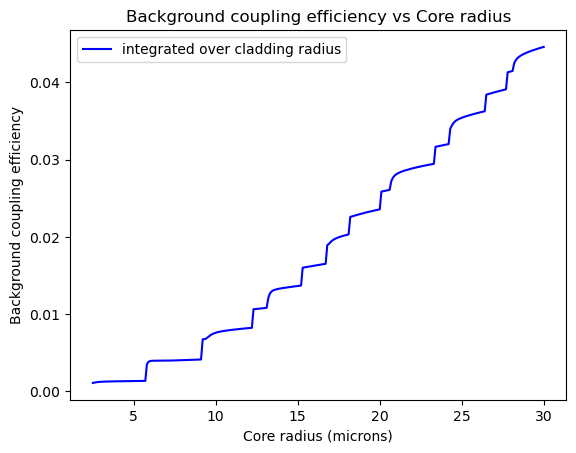

In [108]:
plt.plot(core_radius_range_full*1e6, eta_bg_cladding, color='b', label='integrated over cladding radius')
plt.xlabel('Core radius (microns)')
plt.ylabel('Background coupling efficiency')
plt.title('Background coupling efficiency vs Core radius')
plt.legend()

In [111]:
import numpy as np
import matplotlib.pyplot as plt

# If needed:
# from oh_suppression.coupling_vs_radius_sweeps import eta_background_from_psf_weights


# -----------------------------
# Conversion functions
# -----------------------------
def radius_um_to_V(radius_um):
    radius_m = radius_um * 1e-6
    return 2 * np.pi * radius_m * NA / lam0

def V_to_radius_um(V):
    radius_m = V * lam0 / (2 * np.pi * NA)
    return radius_m * 1e6


# -----------------------------
# Mode label
# -----------------------------
def mode_label(mode):
    """
    Make labels like LP01, LP11 cos, LP11 sin, etc.
    """
    l = mode["l"]
    m = mode["m"]
    angular = mode.get("angular", "cos")

    if l == 0:
        return f"LP{l}{m}"
    else:
        return f"LP{l}{m} {angular}"


# -----------------------------
# Extract background efficiency by mode
# -----------------------------
def extract_background_efficiency_by_mode(results, core_radius_array):
    """
    For each core radius, calculate the background coupling efficiency
    for each LP mode separately.

    Missing modes are stored as NaN because not all modes exist
    at all core radii.
    """

    n_radius = len(core_radius_array)
    mode_eta_dict = {}

    for i, row in enumerate(results):
        decentre_array = row["decentre_array"]
        mode_results_decentre = row["mode_results_decentre"]

        first_decentre_modes = mode_results_decentre[0]

        for mode_index, mode in enumerate(first_decentre_modes):
            label = mode_label(mode)

            if label not in mode_eta_dict:
                mode_eta_dict[label] = np.full(n_radius, np.nan)

            eta_mode_vs_decentre = np.array([
                mode_results_at_d[mode_index]["eta"]
                for mode_results_at_d in mode_results_decentre
            ])

            eta_bg_mode = eta_background_from_psf_weights(
                decentre_array,
                eta_mode_vs_decentre
            )

            mode_eta_dict[label][i] = eta_bg_mode

    return mode_eta_dict

In [114]:
mode_eta_bg_cladding = extract_background_efficiency_by_mode(
    results_bg_mmf_clad_LIGHT,
    core_radius_range_full
)

In [116]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Conversion functions
# -----------------------------
def radius_um_to_V(radius_um):
    radius_m = radius_um * 1e-6
    return 2 * np.pi * radius_m * NA / lam0

def V_to_radius_um(V):
    radius_m = V * lam0 / (2 * np.pi * NA)
    return radius_m * 1e6


# -----------------------------
# Extract only LP01, LP02, LP03, LP04
# -----------------------------
def extract_l0_background_efficiency_by_mode(results, core_radius_array):
    """
    Extract background coupling efficiency for LP01, LP02, LP03, LP04 only.
    These are the l=0 azimuthally symmetric LP modes.
    """

    wanted_modes = {
        (0, 1): "LP01",
        (0, 2): "LP02",
        (0, 3): "LP03",
        (0, 4): "LP04",
    }

    n_radius = len(core_radius_array)

    mode_eta_dict = {
        "LP01": np.full(n_radius, np.nan),
        "LP02": np.full(n_radius, np.nan),
        "LP03": np.full(n_radius, np.nan),
        "LP04": np.full(n_radius, np.nan),
    }

    for i, row in enumerate(results):
        decentre_array = row["decentre_array"]
        mode_results_decentre = row["mode_results_decentre"]

        first_decentre_modes = mode_results_decentre[0]

        for mode_index, mode in enumerate(first_decentre_modes):
            l = mode["l"]
            m = mode["m"]

            if (l, m) not in wanted_modes:
                continue

            label = wanted_modes[(l, m)]

            eta_mode_vs_decentre = np.array([
                mode_results_at_d[mode_index]["eta"]
                for mode_results_at_d in mode_results_decentre
            ])

            eta_bg_mode = eta_background_from_psf_weights(
                decentre_array,
                eta_mode_vs_decentre
            )

            mode_eta_dict[label][i] = eta_bg_mode

    return mode_eta_dict

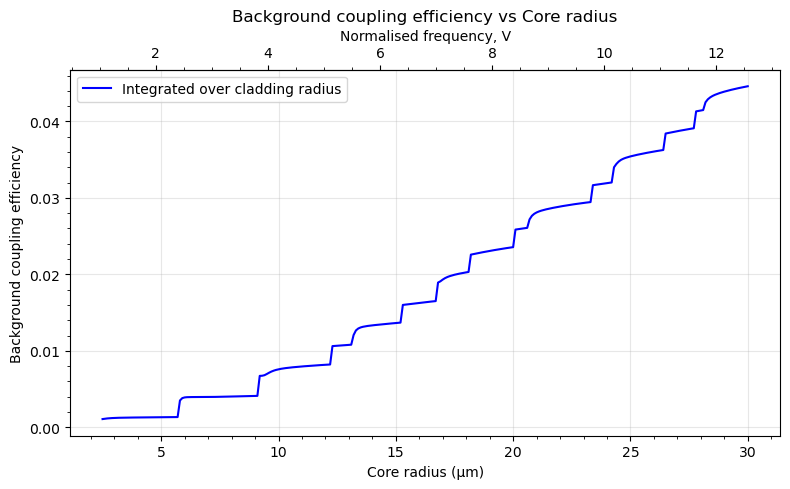

In [121]:
import numpy as np
import matplotlib.pyplot as plt

# Conversion between core radius in microns and normalised frequency V
def radius_um_to_V(radius_um):
    radius_m = radius_um * 1e-6
    return 2 * np.pi * radius_m * NA / lam0

def V_to_radius_um(V):
    radius_m = V * lam0 / (2 * np.pi * NA)
    return radius_m * 1e6


fig, ax1 = plt.subplots(figsize=(8, 5))

ax1.plot(
    core_radius_range_full * 1e6,
    eta_bg_cladding,
    color="b",
    label="Integrated over cladding radius"
)

ax1.set_xlabel("Core radius (µm)")
ax1.set_ylabel("Background coupling efficiency")
ax1.set_title("Background coupling efficiency vs Core radius")

ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

ax1.legend()

plt.tight_layout()
plt.show()

In [117]:
mode_eta_bg_cladding = extract_l0_background_efficiency_by_mode(
    results_bg_mmf_clad_LIGHT,
    core_radius_range_full
)

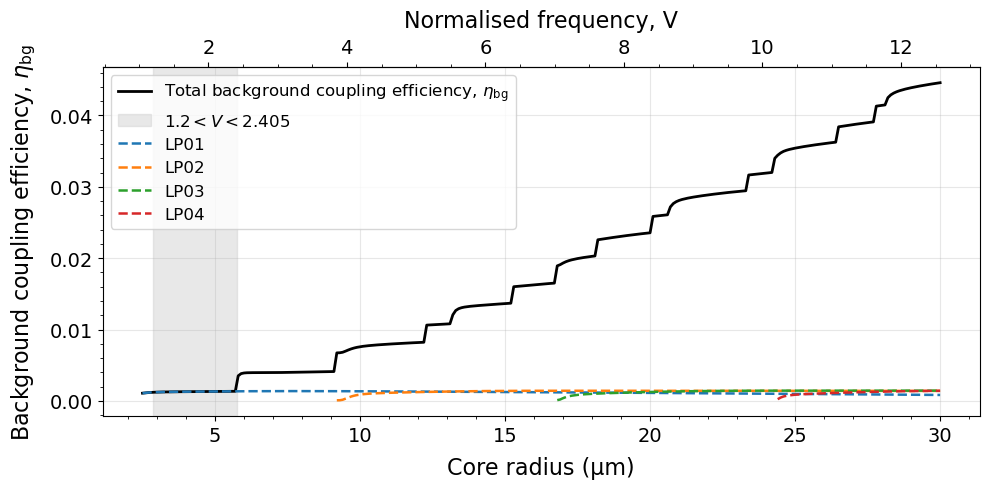

In [118]:
fig, ax1 = plt.subplots(figsize=(10, 5))

# Total background coupling efficiency
ax1.plot(
    core_radius_range_full * 1e6,
    eta_bg_cladding,
    color="black",
    linewidth=2,
    label=r"Total background coupling efficiency, $\eta_{\mathrm{bg}}$"
)

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um(V_1_2),
    V_to_radius_um(V_2_405),
    color="lightgrey",
    alpha=0.5,
    label=r"$1.2 < V < 2.405$"
)

# Plot LP01, LP02, LP03, LP04 only
line_LP01, = ax1.plot(
    core_radius_range_full * 1e6,
    mode_eta_bg_cladding["LP01"],
    linestyle="dashed",
    linewidth=1.8,
    label="LP01"
)

line_LP02, = ax1.plot(
    core_radius_range_full * 1e6,
    mode_eta_bg_cladding["LP02"],
    linestyle="dashed",
    linewidth=1.8,
    label="LP02"
)

line_LP03, = ax1.plot(
    core_radius_range_full * 1e6,
    mode_eta_bg_cladding["LP03"],
    linestyle="dashed",
    linewidth=1.8,
    label="LP03"
)

line_LP04, = ax1.plot(
    core_radius_range_full * 1e6,
    mode_eta_bg_cladding["LP04"],
    linestyle="dashed",
    linewidth=1.8,
    label="LP04"
)

# Axis labels
ax1.set_xlabel("Core radius (µm)", fontsize=16, labelpad=8)
ax1.set_ylabel(r"Background coupling efficiency, $\eta_{\mathrm{bg}}$", fontsize=16, labelpad=8)

ax1.tick_params(axis="x", labelsize=14)
ax1.tick_params(axis="y", labelsize=14)
ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Top x-axis: normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um)
)

ax_top.set_xlabel("Normalised frequency, V", fontsize=14, labelpad=8)
ax_top.tick_params(axis="x", labelsize=14)
ax_top.minorticks_on()

# Legend
ax1.legend(loc="best", fontsize=12, frameon=True)

plt.tight_layout()
plt.show()

In [130]:
import math

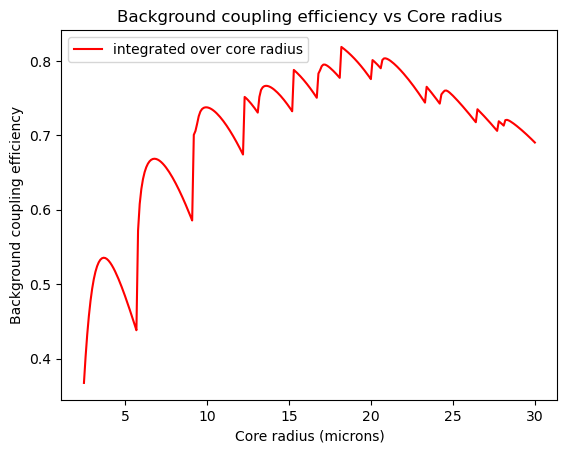

In [185]:
plt.plot(core_radius_range_full*1e6, eta_bg_core, label='integrated over core radius', color='r')
plt.xlabel('Core radius (microns)')
plt.ylabel('Background coupling efficiency')
plt.title('Background coupling efficiency vs Core radius')
plt.legend()

In [98]:
eta_galaxy_clad_dr = [res["eta_extended_source"] for res in results_ext_mmf_clad_LIGHT]
eta_galaxy_core_dr = [res["eta_extended_source"] for res in results_ext_mmf_core_LIGHT]

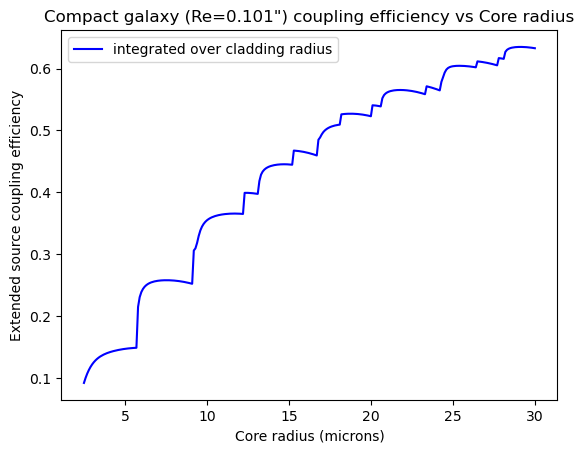

In [186]:
plt.plot(core_radius_range_full*1e6, eta_galaxy_clad_dr, color='b', label='integrated over cladding radius')
plt.xlabel('Core radius (microns)')
plt.ylabel('Extended source coupling efficiency')
plt.title('Compact galaxy (Re=0.101") coupling efficiency vs Core radius')
plt.legend()

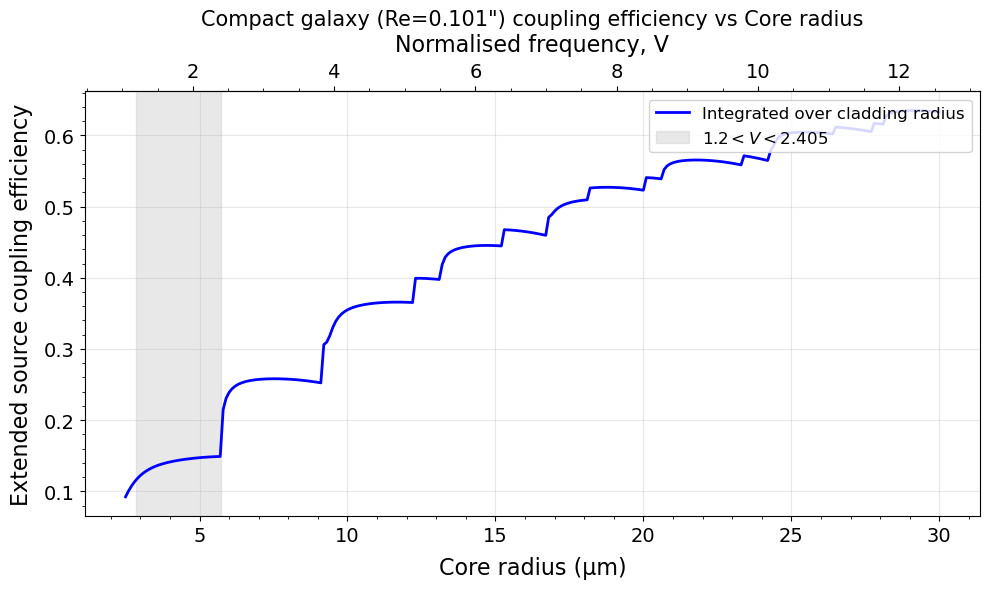

In [144]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(
    core_radius_range_full * 1e6,
    eta_galaxy_clad_dr,
    color="b",
    linewidth=2,
    label="Integrated over cladding radius"
)

ax1.set_xlabel("Core radius (µm)", fontsize=16, labelpad=8)
ax1.set_ylabel("Extended source coupling efficiency", fontsize=16, labelpad=8)
ax1.set_title('Compact galaxy (Re=0.101") coupling efficiency vs Core radius', fontsize=15)

ax1.tick_params(axis="x", labelsize=14)
ax1.tick_params(axis="y", labelsize=14)
ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Top x-axis: normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um)
)

ax_top.set_xlabel("Normalised frequency, V", fontsize=14, labelpad=8)
ax_top.tick_params(axis="x", labelsize=14)
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um(V_1_2),
    V_to_radius_um(V_2_405),
    color="lightgrey",
    alpha=0.5,
    label=r"$1.2 < V < 2.405$"
)

ax1.legend(
    loc="upper right",
    fontsize=12,
    frameon=True,
    framealpha=0.85
)

plt.tight_layout()
plt.show()

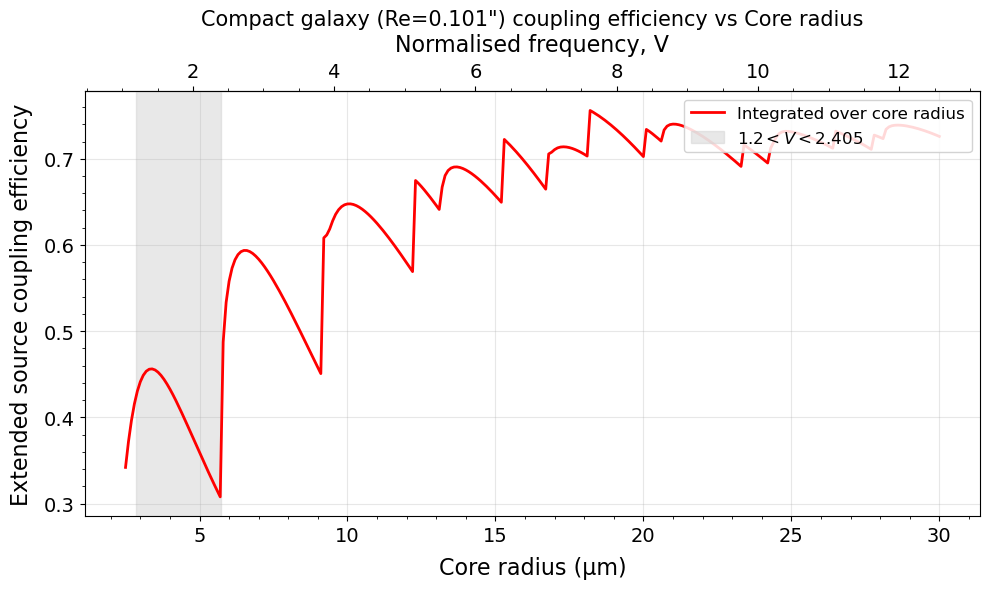

In [146]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(
    core_radius_range_full * 1e6,
    eta_galaxy_core_dr,
    color="r",
    linewidth=2,
    label="Integrated over core radius"
)

ax1.set_xlabel("Core radius (µm)", fontsize=16, labelpad=8)
ax1.set_ylabel("Extended source coupling efficiency", fontsize=16, labelpad=8)
ax1.set_title('Compact galaxy (Re=0.101") coupling efficiency vs Core radius', fontsize=15)

ax1.tick_params(axis="x", labelsize=14)
ax1.tick_params(axis="y", labelsize=14)
ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um)
)

ax_top.set_xlabel("Normalised frequency, V", fontsize=14, labelpad=8)
ax_top.tick_params(axis="x", labelsize=14)
ax_top.minorticks_on()

V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um(V_1_2),
    V_to_radius_um(V_2_405),
    color="lightgrey",
    alpha=0.5,
    label=r"$1.2 < V < 2.405$"
)

ax1.legend(
    loc="upper right",
    fontsize=12,
    frameon=True,
    framealpha=0.85
)

plt.tight_layout()
plt.show()

<>:2: SyntaxWarning: invalid escape sequence '\e'
<>:4: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\e'
<>:4: SyntaxWarning: invalid escape sequence '\ '
/var/folders/pk/ftg5vwzs3r1dhbzyhbqk09580000gp/T/ipykernel_13248/3746888682.py:2: SyntaxWarning: invalid escape sequence '\e'
  plt.title("Compare results via ratio between $\eta_{ext,cladding}$ and $\eta_{ext,core}$")
/var/folders/pk/ftg5vwzs3r1dhbzyhbqk09580000gp/T/ipykernel_13248/3746888682.py:4: SyntaxWarning: invalid escape sequence '\ '
  plt.ylabel('$\\eta_{ext,cladding}\ /\ \\eta_{ext,core}$')


Text(0, 0.5, '$\\eta_{ext,cladding}\\ /\\ \\eta_{ext,core}$')

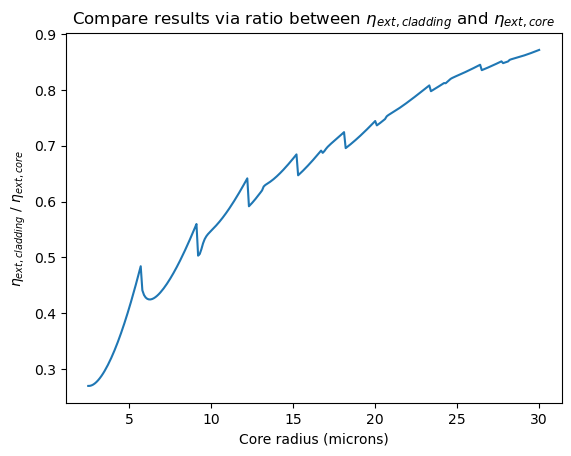

In [187]:
plt.plot(core_radius_range_full*1e6, np.divide(eta_galaxy_clad_dr, eta_galaxy_core_dr))
plt.title("Compare results via ratio between $\eta_{ext,cladding}$ and $\eta_{ext,core}$")
plt.xlabel('Core radius (microns)')
plt.ylabel('$\\eta_{ext,cladding}\ /\ \\eta_{ext,core}$')

In [102]:
# SNR plot for cladding case

I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_array = np.zeros_like(core_radius_range_full)
snr_array = np.zeros_like(core_radius_range_full)
signal_array = np.zeros_like(core_radius_range_full)
background_array = np.zeros_like(core_radius_range_full)

for i, a in enumerate(core_radius_range_full): 
    # # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV = plate_scale_demag * 2*a # in arcseconds 

    # r_FOV = np.linspace(0, FOV, 10000) * plate_scale_demag # Convert FOV from arcseconds to meters at the fibre input plane for the core region
    
    # Signal = 2*np.pi * integrate.simpson(I_image * fibre_r, x=fibre_r) # Total signal coupled into the fibre, integrating over the fibre cross-section
    Background_area = np.pi * I_flat * (FOV / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    # signal_array = np.array(eta_galaxy_clad_dr) #for now ignore the integrated brightness of galaxy

    # background_array = np.array(eta_bg_cladding) * I_flat #for now ignore the integrated brightness of background

    signal = eta_galaxy_clad_dr[i]
    background = eta_bg_cladding[i] * I_flat

    snr = signal / np.sqrt(Background_area * background) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_array[i] = FOV
    snr_array[i] = snr
    signal_array[i] = signal
    background_array[i] = background



In [103]:
snr_array

array([122.54189571, 125.45306809, 127.09151676, 127.710439  ,
       127.53292681, 126.74608898, 125.50272121, 123.92514951,
       122.10937823, 120.1302615 , 118.04515487, 115.89768064,
       113.72090754, 111.53939927, 109.37136883, 107.22993841,
       105.12432803, 103.0610174 , 101.04415453,  99.07631592,
        97.15874842,  95.29169069,  93.47483684,  91.70730371,
        89.98794127,  88.31528738,  86.68767696,  85.10345599,
        83.56087745,  82.05824161,  80.59380876,  79.16585092,
        77.77275051,  68.14730098,  68.93969528,  69.37133153,
        69.41227888,  69.17203135,  68.7373961 ,  68.1684135 ,
        67.50603698,  66.77861623,  66.00616196,  65.20308665,
        64.37986399,  63.54414931,  62.70158433,  61.85640448,
        61.01186681,  60.17040176,  59.33381496,  58.50342153,
        57.68022551,  56.86502115,  56.05837245,  55.26065834,
        54.47211605,  53.69289428,  52.92312465,  52.16285699,
        51.41207399,  50.67071897,  49.93869966,  49.21

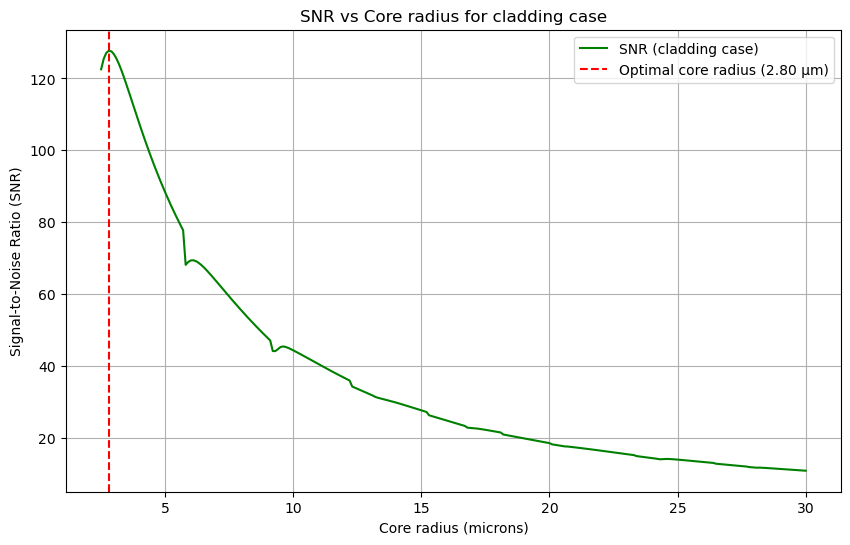

In [104]:
# Plot SNR vs Core radius

plt.figure(figsize=(10, 6))
plt.plot(core_radius_range_full*1e6, snr_array, color='g', label='SNR (cladding case)')
plt.axvline(core_radius_range_full[np.argmax(snr_array)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_full[np.argmax(snr_array)] * 1e6:.2f} µm)")
plt.xlabel('Core radius (microns)')
plt.ylabel('Signal-to-Noise Ratio (SNR)')
plt.title('SNR vs Core radius for cladding case')
plt.grid()
plt.legend()

In [105]:
# SNR plot for core case

I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_array = np.zeros_like(core_radius_range_full)
snr_array_core = np.zeros_like(core_radius_range_full)
signal_array_core = np.zeros_like(core_radius_range_full)
background_array_core = np.zeros_like(core_radius_range_full)

for i, a in enumerate(core_radius_range_full): 
    # # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV = plate_scale_demag * 2*a # in arcseconds 

    # r_FOV = np.linspace(0, FOV, 10000) * plate_scale_demag # Convert FOV from arcseconds to meters at the fibre input plane for the core region
    
    # Signal = 2*np.pi * integrate.simpson(I_image * fibre_r, x=fibre_r) # Total signal coupled into the fibre, integrating over the fibre cross-section
    Background_area = np.pi * I_flat * (FOV / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    # signal_array = np.array(eta_galaxy_clad_dr) #for now ignore the integrated brightness of galaxy

    # background_array = np.array(eta_bg_cladding) * I_flat #for now ignore the integrated brightness of background

    signal = eta_galaxy_core_dr[i]
    background = eta_bg_core[i] * I_flat

    snr = signal / np.sqrt(Background_area * background) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_array[i] = FOV
    snr_array_core[i] = snr
    signal_array_core[i] = signal
    background_array_core[i] = background


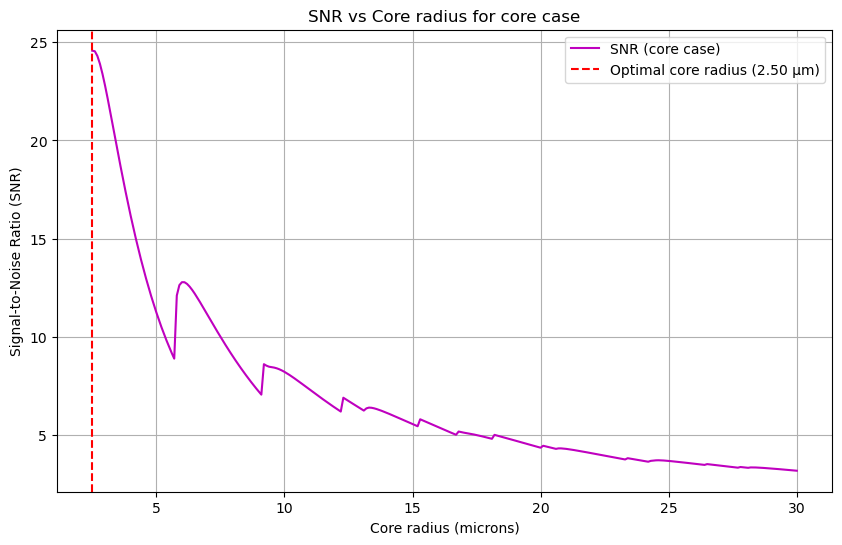

In [106]:
# Plot SNR vs Core radius for core case

plt.figure(figsize=(10, 6))
plt.plot(core_radius_range_full*1e6, snr_array_core, color='m', label='SNR (core case)')
plt.axvline(core_radius_range_full[np.argmax(snr_array_core)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_full[np.argmax(snr_array_core)] * 1e6:.2f} µm)")
plt.xlabel('Core radius (microns)')
plt.ylabel('Signal-to-Noise Ratio (SNR)')
plt.title('SNR vs Core radius for core case')
plt.grid()
plt.legend()